In [4]:
import pandas as pd
import numpy as np

In [5]:
df_train = pd.read_csv("train.csv")  # note that all next columns are present , it has been done that way

df_test = pd.read_csv("test.csv")

## Split into folds based on date

In [6]:


dev = df_train.copy()

dev["date"] = pd.to_datetime(dev["date"])
dev = dev.sort_values(["id", "date"])


dev["sleep_hours"] = dev["sleep_duration"] / 3_600_000

folds = []

for k in range(3):

    fit_idx = []
    val_idx = []

    for pid, group in dev.groupby("id"):
        n = len(group)

        # skip that participant if  less than 10 observation 
        if n < 10:
            continue

        # Boundaries at 40%, 60%, 80%, 100%
        cuts = [
            int(np.floor(n * fraction))
            for fraction in [0.4, 0.6, 0.8, 1.0]
        ]

        train_end = cuts[k]
        val_end = cuts[k + 1]

        # Leaving one   oobserver at boundary
        fit_idx.extend(group.index[:train_end - 1])
        val_idx.extend(group.index[train_end:val_end])

    folds.append((fit_idx, val_idx))

    fold_fit = dev.loc[fit_idx]
    fold_val = dev.loc[val_idx]

    print(f"FOLD {k + 1}")
    print("Training samples:", len(fold_fit))
    print("Validation samples:", len(fold_val))
    print("Validation participants:",
          fold_val["id"].nunique())

    # no rows overlap check
    assert set(fit_idx).isdisjoint(val_idx)

    # Check chronological order is maintened
    for pid, group_val in fold_val.groupby("id"):
        group_fit = fold_fit[fold_fit["id"] == pid]

        assert (
            group_fit["date"].max()
            < group_val["date"].min()
        )



FOLD 1
Training samples: 629
Validation samples: 351
Validation participants: 48
FOLD 2
Training samples: 980
Validation samples: 350
Validation participants: 48
FOLD 3
Training samples: 1330
Validation samples: 368
Validation participants: 48


## 1) 8 Baseline Features

In [7]:

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    average_precision_score
)

baseline_features = [
    "steps",
    "calories",
    "sedentary_minutes",
    "lightly_active_minutes",
    "moderately_active_minutes",
    "very_active_minutes",
    "bpm",
    "sleep_hours"
]

next_cols = [
    "ALERT_next",
    "HAPPY_next",
    "NEUTRAL_next",
    "RESTED/RELAXED_next",
    "SAD_next",
    "TENSE/ANXIOUS_next",
    "TIRED_next"
]

cv_results = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    fold_fit = dev.loc[fit_idx]
    fold_val = dev.loc[val_idx]

    X_fit = fold_fit[baseline_features]
    X_val = fold_val[baseline_features]

    for target in next_cols:

        y_fit = fold_fit[target].astype(int)
        y_val = fold_val[target].astype(int)

        if y_fit.nunique() < 2:
            print(f"Skipping {target} in fold {fold_num}: "
                  "only one training class")
            continue

        models = {
            "Dummy": DummyClassifier(strategy="prior"),

            "Logistic": make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler(),
                LogisticRegression(max_iter=2000)
            )
        }

        for name, model in models.items():

            model.fit(X_fit, y_fit)

            y_pred = model.predict(X_val)
            y_prob = model.predict_proba(X_val)[:, 1]

            auc = (
                roc_auc_score(y_val, y_prob)
                if y_val.nunique() == 2 else np.nan
            )

            pr_auc = (
                average_precision_score(y_val, y_prob)
                if y_val.sum() > 0 else np.nan
            )

            cv_results.append({
                "Fold": fold_num,
                "Mood": target,
                "Model": name,
                "Accuracy": accuracy_score(y_val, y_pred),
                "F1": f1_score(
                    y_val, y_pred, zero_division=0
                ),
                "AUC": auc,
                "PR_AUC": pr_auc
            })

cv_results_df = pd.DataFrame(cv_results)

print("RESULTS FOR EACH FOLD")
print(cv_results_df.round(3).to_string(index=False))


RESULTS FOR EACH FOLD
 Fold                Mood    Model  Accuracy    F1   AUC  PR_AUC
    1          ALERT_next    Dummy     0.883 0.000 0.500   0.117
    1          ALERT_next Logistic     0.886 0.048 0.679   0.239
    1          HAPPY_next    Dummy     0.704 0.000 0.500   0.296
    1          HAPPY_next Logistic     0.704 0.000 0.514   0.319
    1        NEUTRAL_next    Dummy     0.744 0.000 0.500   0.256
    1        NEUTRAL_next Logistic     0.744 0.000 0.617   0.355
    1 RESTED/RELAXED_next    Dummy     0.618 0.000 0.500   0.382
    1 RESTED/RELAXED_next Logistic     0.573 0.292 0.595   0.428
    1            SAD_next    Dummy     0.932 0.000 0.500   0.068
    1            SAD_next Logistic     0.932 0.000 0.534   0.080
    1  TENSE/ANXIOUS_next    Dummy     0.772 0.000 0.500   0.228
    1  TENSE/ANXIOUS_next Logistic     0.772 0.024 0.521   0.258
    1          TIRED_next    Dummy     0.567 0.000 0.500   0.433
    1          TIRED_next Logistic     0.553 0.290 0.486   0.441
   

In [8]:

cv_summary = (
    cv_results_df
    .groupby(["Mood", "Model"])
    [["Accuracy", "F1", "AUC", "PR_AUC"]]
    .agg(["mean", "std"])
)

print("THREE-FOLD CROSS-VALIDATION SUMMARY")
print(cv_summary.round(3).to_string())


THREE-FOLD CROSS-VALIDATION SUMMARY
                             Accuracy            F1           AUC        PR_AUC       
                                 mean    std   mean    std   mean    std   mean    std
Mood                Model                                                             
ALERT_next          Dummy       0.884  0.010  0.000  0.000  0.500  0.000  0.116  0.010
                    Logistic    0.881  0.014  0.016  0.027  0.666  0.018  0.207  0.029
HAPPY_next          Dummy       0.711  0.018  0.000  0.000  0.500  0.000  0.289  0.018
                    Logistic    0.711  0.018  0.000  0.000  0.497  0.046  0.298  0.052
NEUTRAL_next        Dummy       0.713  0.033  0.000  0.000  0.500  0.000  0.287  0.033
                    Logistic    0.715  0.032  0.012  0.011  0.542  0.065  0.346  0.043
RESTED/RELAXED_next Dummy       0.609  0.025  0.000  0.000  0.500  0.000  0.391  0.025
                    Logistic    0.600  0.031  0.261  0.028  0.565  0.028  0.447  0.029
SAD_nex


It suggests our eight wearable features contain some information that helps distinguish observations followed by ALERT from those not followed by ALERT.
Notice that the PR-AUC also improves from the Dummy baseline's 0.116 to 0.207 on average.
 An AUC of 0.666 indicates modest discrimination, SAD is interesting, but unstable
Our SAD AUCs are:
- Fold 1: 0.534
- Fold 2: 0.723
- Fold 3: 0.524
Fold 2 looks promising, but the other two are close to random ranking.

 SAD is our rarest label. A small number of positive observations can cause substantial variations in evaluation metrics.
T
 The remaining moods show weak discrimination
For HAPPY, NEUTRAL, TENSE/ANXIOUS, and TIRED, AUC values generally hover near 0.5.
RESTED/RELAXED performs somewhat better, with an average AUC of 0.565, but this is still modest.
Our current eight-feature logistic regression models are not performing particularly well for most moods.
 we may need to establish a simple baseline before trying additional features.


In [9]:



prediction_summary = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    fold_fit = dev.loc[fit_idx]
    fold_val = dev.loc[val_idx]

    X_fit = fold_fit[baseline_features]
    X_val = fold_val[baseline_features]

    for target in next_cols:

        y_fit = fold_fit[target].astype(int)
        y_val = fold_val[target].astype(int)

        model = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(max_iter=2000)
        )

        model.fit(X_fit, y_fit)

        probabilities = model.predict_proba(X_val)[:, 1]
        predictions = (probabilities >= 0.5).astype(int)

        prediction_summary.append({
            "Fold": fold_num,
            "Mood": target,
            "Actual positives": y_val.sum(),
            "Predicted positives": predictions.sum(),
            "Max probability": probabilities.max(),
            "Mean probability": probabilities.mean()
        })

prediction_df = pd.DataFrame(prediction_summary)

print(prediction_df.round(3).to_string(index=False))


 Fold                Mood  Actual positives  Predicted positives  Max probability  Mean probability
    1          ALERT_next                41                    1            0.543             0.179
    1          HAPPY_next               104                    0            0.481             0.312
    1        NEUTRAL_next                90                    0            0.443             0.229
    1 RESTED/RELAXED_next               134                   78            0.748             0.422
    1            SAD_next                24                    0            0.118             0.056
    1  TENSE/ANXIOUS_next                80                    2            0.569             0.244
    1          TIRED_next               152                   69            0.919             0.448
    2          ALERT_next                44                    3            0.597             0.165
    2          HAPPY_next                94                    0            0.450             0.314


This explains why HAPPY has an F1 score of zero.
Suppose the model predicts the following probabilities for five observations:

[0.12, 0.28, 0.35, 0.42, 0.48]

At the default threshold of 0.5, every prediction becomes zero.
But notice that the probabilities are different. The model is not assigning everyone the same probability.
The important question is whether higher predicted probabilities actually correspond to a greater likelihood of HAPPY being recorded.
Our ROC AUC of approximately 0.50 suggests that, with the current features, the model isn't doing much better than random ranking for HAPPY.
So simply lowering the classification threshold wouldn't necessarily fix the underlying predictive weakness.

## 2) Adding 2 more features to see whether there is improvement

In [10]:

# Compare the original 8-feature model with a 10-feature model

feature_sets = {
    "8 features": baseline_features,
    "10 features": baseline_features + [
        "resting_hr",
        "sleep_efficiency"
    ]
}

comparison_results = []

for feature_name, features in feature_sets.items():

    for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

        fold_fit = dev.loc[fit_idx]
        fold_val = dev.loc[val_idx]

        X_fit = fold_fit[features]
        X_val = fold_val[features]

        for target in next_cols:

            y_fit = fold_fit[target].astype(int)
            y_val = fold_val[target].astype(int)

            model = make_pipeline(
                SimpleImputer(strategy="median"),
                StandardScaler(),
                LogisticRegression(max_iter=2000)
            )

            model.fit(X_fit, y_fit)

            probabilities = model.predict_proba(X_val)[:, 1]

            comparison_results.append({
                "Features": feature_name,
                "Fold": fold_num,
                "Mood": target,
                "AUC": (
                    roc_auc_score(y_val, probabilities)
                    if y_val.nunique() == 2 else np.nan
                ),
                "PR_AUC": (
                    average_precision_score(y_val, probabilities)
                    if y_val.sum() > 0 else np.nan
                )
            })

comparison_df = pd.DataFrame(comparison_results)

summary = (
    comparison_df
    .groupby(["Mood", "Features"])[["AUC", "PR_AUC"]]
    .mean()
)

print(summary.round(3).to_string())


                                   AUC  PR_AUC
Mood                Features                  
ALERT_next          10 features  0.680   0.220
                    8 features   0.666   0.207
HAPPY_next          10 features  0.489   0.289
                    8 features   0.497   0.298
NEUTRAL_next        10 features  0.550   0.351
                    8 features   0.542   0.346
RESTED/RELAXED_next 10 features  0.577   0.446
                    8 features   0.565   0.447
SAD_next            10 features  0.600   0.087
                    8 features   0.594   0.083
TENSE/ANXIOUS_next  10 features  0.519   0.228
                    8 features   0.512   0.226
TIRED_next          10 features  0.532   0.409
                    8 features   0.521   0.401


In [11]:

# Compare the two feature sets separately for each fold

auc_by_fold = comparison_df.pivot(
    index=["Mood", "Fold"],
    columns="Features",
    values="AUC"
)

# Calculate the improvement from adding two features
auc_by_fold["Improvement"] = (
    auc_by_fold["10 features"]
    - auc_by_fold["8 features"]
)

print("AUC COMPARISON BY FOLD")
print(auc_by_fold.round(3).to_string())


AUC COMPARISON BY FOLD
Features                  10 features  8 features  Improvement
Mood                Fold                                      
ALERT_next          1           0.691       0.679        0.012
                    2           0.678       0.675        0.003
                    3           0.672       0.645        0.026
HAPPY_next          1           0.491       0.514       -0.023
                    2           0.450       0.444        0.006
                    3           0.527       0.531       -0.004
NEUTRAL_next        1           0.617       0.617       -0.000
                    2           0.523       0.515        0.008
                    3           0.512       0.495        0.016
RESTED/RELAXED_next 1           0.611       0.595        0.016
                    2           0.556       0.561       -0.005
                    3           0.563       0.539        0.024
SAD_next            1           0.547       0.534        0.013
                    2           

## 3) Adding categorical features like age ,bmi and gender

Making the bmi into categorical grouping first

In [12]:




dev_demo = dev.copy()

def bmi_group(value):
    if pd.isna(value):
        return np.nan

    if value == "<19":
        return "<19"

    if value in [">=25", ">=30"]:
        return ">=25"

    value = float(value)

    if value < 19:
        return "<19"
    elif value < 25:
        return "19-<25"
    else:
        return ">=25"

dev_demo["bmi_group"] = dev_demo["bmi"].apply(bmi_group)

demographic_features = ["age", "gender", "bmi_group"]

print("AGE")
print(dev_demo["age"].value_counts(dropna=False))

print("\nGENDER")
print(dev_demo["gender"].value_counts(dropna=False))

print("\nBMI GROUP")
print(dev_demo["bmi_group"].value_counts(dropna=False))


AGE
age
>=30    954
<30     798
NaN      63
Name: count, dtype: int64

GENDER
gender
MALE      1094
FEMALE     662
NaN         59
Name: count, dtype: int64

BMI GROUP
bmi_group
19-<25    1125
>=25       524
<19        103
NaN         63
Name: count, dtype: int64


In [15]:


from sklearn.preprocessing import  OneHotEncoder


from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# Original 10 numerical features
numeric_features = baseline_features + [
    "resting_hr",
    "sleep_efficiency"
]

# New demographic features
categorical_features = [
    "age",
    "gender",
    "bmi_group"
]


dev_demo = dev_demo.copy()

for col in categorical_features:
    dev_demo[col] = (
        dev_demo[col]
        .astype("string")
        .fillna("Missing")
        .astype(str)
    )

# Preprocessing for numerical features
numeric_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

# Preprocessing for categorical features
categorical_pipeline = OneHotEncoder(
    handle_unknown="ignore"
)

# Combine the two preprocessing pipelines
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_pipeline, numeric_features),
        ("cat", categorical_pipeline, categorical_features)
    ]
)

comparison_results_demo = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    fold_fit = dev_demo.loc[fit_idx]
    fold_val = dev_demo.loc[val_idx]

    for target in next_cols:

        y_fit = fold_fit[target].astype(int)
        y_val = fold_val[target].astype(int)

        # Model B: 10 numerical features
        model_B = make_pipeline(
            SimpleImputer(strategy="median"),
            StandardScaler(),
            LogisticRegression(max_iter=2000)
        )

        # Model C: 10 numerical + 3 categorical features
        model_C = make_pipeline(
            preprocessor,
            LogisticRegression(max_iter=2000)
        )

        models = {
            "10 features": (
                model_B,
                numeric_features
            ),
            "13 features": (
                model_C,
                numeric_features + categorical_features
            )
        }

        for name, (model, features) in models.items():

            X_fit = fold_fit[features]
            X_val = fold_val[features]

            model.fit(X_fit, y_fit)

            probabilities = model.predict_proba(X_val)[:, 1]

            auc = (
                roc_auc_score(y_val, probabilities)
                if y_val.nunique() == 2 else np.nan
            )

            pr_auc = (
                average_precision_score(y_val, probabilities)
                if y_val.sum() > 0 else np.nan
            )

            comparison_results_demo.append({
                "Fold": fold_num,
                "Mood": target,
                "Features": name,
                "AUC": auc,
                "PR_AUC": pr_auc
            })

comparison_demo_df = pd.DataFrame(
    comparison_results_demo
)

summary_demo = (
    comparison_demo_df
    .groupby(["Mood", "Features"])[["AUC", "PR_AUC"]]
    .mean()
)

print("MODEL COMPARISON")
print(summary_demo.round(3).to_string())


MODEL COMPARISON
                                   AUC  PR_AUC
Mood                Features                  
ALERT_next          10 features  0.680   0.220
                    13 features  0.706   0.237
HAPPY_next          10 features  0.489   0.289
                    13 features  0.461   0.270
NEUTRAL_next        10 features  0.550   0.351
                    13 features  0.553   0.368
RESTED/RELAXED_next 10 features  0.577   0.446
                    13 features  0.643   0.521
SAD_next            10 features  0.600   0.087
                    13 features  0.626   0.168
TENSE/ANXIOUS_next  10 features  0.519   0.228
                    13 features  0.537   0.236
TIRED_next          10 features  0.532   0.409
                    13 features  0.594   0.462


RESTED, TIRED and SAD improves while happiness not much

In [16]:

# Compare 10-feature and 13-feature models
# for every mood and chronological fold

auc_by_fold = comparison_demo_df.pivot(
    index=["Mood", "Fold"],
    columns="Features",
    values="AUC"
)

auc_by_fold["Improvement"] = (
    auc_by_fold["13 features"]
    - auc_by_fold["10 features"]
)

print("AUC COMPARISON BY FOLD")
print(auc_by_fold.round(3).to_string())




AUC COMPARISON BY FOLD
Features                  10 features  13 features  Improvement
Mood                Fold                                       
ALERT_next          1           0.691        0.720        0.029
                    2           0.678        0.709        0.031
                    3           0.672        0.690        0.018
HAPPY_next          1           0.491        0.461       -0.029
                    2           0.450        0.436       -0.014
                    3           0.527        0.486       -0.041
NEUTRAL_next        1           0.617        0.596       -0.021
                    2           0.523        0.529        0.006
                    3           0.512        0.535        0.024
RESTED/RELAXED_next 1           0.611        0.676        0.065
                    2           0.556        0.639        0.083
                    3           0.563        0.614        0.051
SAD_next            1           0.547        0.563        0.016
                 

Adding age, gender, and BMI improves several mood classifiers consistently across all three chronological folds. That is our strongest feature-expansion result so far.

The fact that demographic information produces larger improvements suggests that between-participant differences may be important for predicting some mood labels.
But there are two qualifications:
- The demographics are largely constant within participants, so these gains don't establish that demographics explain daily mood changes.


## 4) Adding todays mood columns

Initial check on whether a person is happy tomorrow given they were happy yesterdau

In [17]:


mood_cols = [
    "ALERT", "HAPPY", "NEUTRAL",
    "RESTED/RELAXED", "SAD",
    "TENSE/ANXIOUS", "TIRED"
]


mood_history = df_train.copy()

results = []

for mood in mood_cols:

    target = f"{mood}_next"

    # Only observations with today's mood recorded
    subset = mood_history.dropna(subset=[mood, target])

    today_0 = subset[subset[mood] == 0]
    today_1 = subset[subset[mood] == 1]

    results.append({
        "Mood": mood,
        "N": len(subset),
        "Today positives": len(today_1),
        "P(next=1 | today=0)": (
            today_0[target].mean()
            if len(today_0) else float("nan")
        ),
        "P(next=1 | today=1)": (
            today_1[target].mean()
            if len(today_1) else float("nan")
        )
    })

persistence_df = pd.DataFrame(results)

print(persistence_df.round(3).to_string(index=False))


          Mood    N  Today positives  P(next=1 | today=0)  P(next=1 | today=1)
         ALERT 1613              236                0.103                0.407
         HAPPY 1613              497                0.247                0.447
       NEUTRAL 1613              421                0.168                0.553
RESTED/RELAXED 1613              662                0.292                0.571
           SAD 1613              100                0.050                0.240
 TENSE/ANXIOUS 1613              366                0.166                0.418
         TIRED 1613              652                0.328                0.509


There is good indication that the todays mood affects tomorrows mood

In [18]:


numeric_features = baseline_features + [
    "resting_hr",
    "sleep_efficiency"
]

demographic_features = [
    "age", "gender", "bmi_group"
]

historical_moods = [
    "ALERT", "HAPPY", "NEUTRAL",
    "RESTED/RELAXED", "SAD",
    "TENSE/ANXIOUS", "TIRED"
]

results_history = []

for fold_num, (fit_idx, val_idx) in enumerate(folds, start=1):

    fold_fit = dev_demo.loc[fit_idx]
    fold_val = dev_demo.loc[val_idx]

    for target in next_cols:

        y_fit = fold_fit[target].astype(int)
        y_val = fold_val[target].astype(int)

        for name, use_history in [
            ("13 features", False),
            ("20 features", True)
        ]:

            # Numerical preprocessing
            transformers = [
                (
                    "num",
                    make_pipeline(
                        SimpleImputer(strategy="median"),
                        StandardScaler()
                    ),
                    numeric_features
                ),
                (
                    "demo",
                    OneHotEncoder(handle_unknown="ignore"),
                    demographic_features
                )
            ]

            features = numeric_features + demographic_features

            if use_history:
                transformers.append(
                    (
                        "mood_history",
                        make_pipeline(
                            SimpleImputer(
                                strategy="constant",
                                fill_value=-1
                            ),
                            OneHotEncoder(handle_unknown="ignore")
                        ),
                        historical_moods
                    )
                )

                features = features + historical_moods

            preprocessor = ColumnTransformer(transformers)

            model = make_pipeline(
                preprocessor,
                LogisticRegression(max_iter=2000)
            )

            model.fit(fold_fit[features], y_fit)

            probabilities = model.predict_proba(
                fold_val[features]
            )[:, 1]

            results_history.append({
                "Fold": fold_num,
                "Mood": target,
                "Model": name,
                "AUC": (
                    roc_auc_score(y_val, probabilities)
                    if y_val.nunique() == 2 else np.nan
                ),
                "PR_AUC": (
                    average_precision_score(y_val, probabilities)
                    if y_val.sum() > 0 else np.nan
                )
            })

history_df = pd.DataFrame(results_history)

history_summary = (
    history_df
    .groupby(["Mood", "Model"])[["AUC", "PR_AUC"]]
    .mean()
)

print(history_summary.round(3).to_string())


                                   AUC  PR_AUC
Mood                Model                     
ALERT_next          13 features  0.706   0.237
                    20 features  0.758   0.336
HAPPY_next          13 features  0.461   0.270
                    20 features  0.585   0.375
NEUTRAL_next        13 features  0.553   0.368
                    20 features  0.703   0.515
RESTED/RELAXED_next 13 features  0.643   0.521
                    20 features  0.690   0.596
SAD_next            13 features  0.626   0.168
                    20 features  0.704   0.174
TENSE/ANXIOUS_next  13 features  0.537   0.236
                    20 features  0.672   0.351
TIRED_next          13 features  0.594   0.462
                    20 features  0.618   0.491


This improved the results showing that todays mood is most likely affected by what the persons mood is yesterday

In [19]:

# Compare ROC AUC for every fold

auc_history = history_df.pivot(
    index=["Mood", "Fold"],
    columns="Model",
    values="AUC"
)

auc_history["Improvement"] = (
    auc_history["20 features"]
    - auc_history["13 features"]
)

print("AUC IMPROVEMENT BY FOLD")
print(auc_history.round(3).to_string())





AUC IMPROVEMENT BY FOLD
Model                     13 features  20 features  Improvement
Mood                Fold                                       
ALERT_next          1           0.720        0.706       -0.014
                    2           0.709        0.789        0.080
                    3           0.690        0.778        0.088
HAPPY_next          1           0.461        0.556        0.094
                    2           0.436        0.565        0.129
                    3           0.486        0.634        0.148
NEUTRAL_next        1           0.596        0.654        0.058
                    2           0.529        0.726        0.197
                    3           0.535        0.729        0.194
RESTED/RELAXED_next 1           0.676        0.684        0.008
                    2           0.639        0.724        0.084
                    3           0.614        0.662        0.048
SAD_next            1           0.563        0.623        0.060
                

In [41]:
history_summary.iloc[2,0]

np.float64(0.46115883925663775)

In [37]:
history_summary

AUC    PR_AUC
Mood                Model                          
ALERT_next          13 features  0.706348  0.237201
                    20 features  0.757693  0.336184
HAPPY_next          13 features  0.461159  0.270411
                    20 features  0.585059  0.375423
NEUTRAL_next        13 features  0.553494  0.367836
                    20 features  0.702970  0.514636
RESTED/RELAXED_next 13 features  0.643255  0.521023
                    20 features  0.689869  0.596240
SAD_next            13 features  0.625682  0.168093
                    20 features  0.704027  0.173854
TENSE/ANXIOUS_next  13 features  0.536921  0.236021
                    20 features  0.671671  0.350976
TIRED_next          13 features  0.593845  0.462009
                    20 features  0.617687  0.490648

In [50]:
A= np.zeros((7,4))

for i in range(0,7):

    A[i,0]= summary.iloc[1+2*i,0]  # 8
    A[i,1]= summary.iloc[0+2*i,0]   # 10
    A[i,2]= history_summary.iloc[0+2*i,0]
    A[i,3]= history_summary.iloc[1+2*i,0]
  
A



array([[0.66640628, 0.68034024, 0.70634796, 0.75769303],
       [0.49659106, 0.48927796, 0.46115884, 0.58505931],
       [0.54246422, 0.55043733, 0.55349423, 0.70296982],
       [0.5651582 , 0.57692624, 0.64325528, 0.68986863],
       [0.59377216, 0.59990934, 0.62568228, 0.70402744],
       [0.51171229, 0.51854643, 0.53692103, 0.67167087],
       [0.5214637 , 0.53157411, 0.59384521, 0.61768713]])

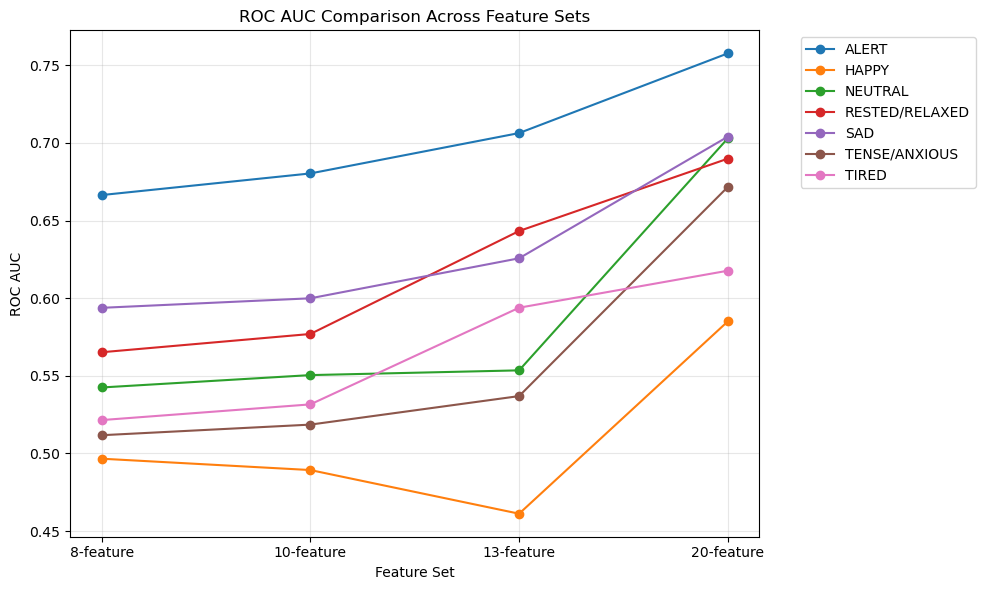

In [52]:

import matplotlib.pyplot as plt

Featrs = ["8-feature", "10-feature", "13-feature", "20-feature"]

plt.figure(figsize=(10, 6))

for i, mood in enumerate(mood_cols):
    plt.plot(Featrs, A[i, :], marker="o", label=mood)

plt.xlabel("Feature Set")
plt.ylabel("ROC AUC")
plt.title("ROC AUC Comparison Across Feature Sets")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:

import pickle
from pathlib import Path


output_dir = Path("model_data")
output_dir.mkdir(exist_ok=True)

# Save developed and final test datasets
dev_demo.to_pickle(output_dir / "dev_demo.pkl")
df_test.to_pickle(output_dir / "df_test.pkl")


with open(output_dir / "folds.pkl", "wb") as f:
    pickle.dump(folds, f)

